In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [11]:
df = pd.read_csv("C:\\Users\\Chinmaya holla\\Desktop\\Airpollution\\Data\\Processed_data\\master_cleaned_data.csv")
# Convert Timestamp to datetime
df['Timestamp'] = pd.to_datetime(df['Timestamp'], dayfirst=True)

# PIVOT: Turn Stations into Columns (Spatial Step)
# This creates a table where each column is a station (BTM, Peenya, etc.)
df_pivot = df.pivot_table(index='Timestamp', columns='Station', values='NO')

# HANDLE MISSING VALUES
# Interpolate to fill gaps linearly & resample to daily frequency
df_pivot = df_pivot.interpolate(method='time').resample('D').mean().bfill().ffill()

print(f"Data Shape: {df_pivot.shape}")
print(f"Stations: {df_pivot.columns.tolist()}")

Data Shape: (2192, 8)
Stations: ['BTM', 'BapujiNagar', 'Hombegowda', 'Jayanagar', 'Kadabasenahalli', 'Peenya', 'RVCE', 'Silkboard']


In [12]:
train_df = df_pivot[df_pivot.index.year < 2024]
test_df = df_pivot[df_pivot.index.year == 2024]

In [13]:
# ==========================================
# 3. SCALE DATA (0 to 1)
# ==========================================
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_train = scaler.fit_transform(train_df)
scaled_test = scaler.transform(test_df)

# Save the scaler for later use in your API
joblib.dump(scaler, 'aqi_scaler.pkl')

# ==========================================
# 4. CREATE SEQUENCES (Sliding Window)
# ==========================================
def create_sequences(data, time_steps=60):
    X, y = [], []
    for i in range(len(data) - time_steps):
        # Input: Past 60 days of ALL stations
        X.append(data[i : i + time_steps])
        # Output: The next day for ALL stations
        y.append(data[i + time_steps])
    return np.array(X), np.array(y)

TIME_STEPS = 60
X_train, y_train = create_sequences(scaled_train, TIME_STEPS)
X_test, y_test = create_sequences(scaled_test, TIME_STEPS)

print(f"Training Input Shape: {X_train.shape}")

Training Input Shape: (1766, 60, 8)


In [14]:
# ==========================================
# 5. BUILD HYBRID CNN-LSTM MODEL
# ==========================================
print("Building CNN-LSTM Model...")
model = Sequential()

# --- CNN LAYER (Feature Extractor) ---
# Extracts short-term local patterns (e.g., weekly spikes)
model.add(Conv1D(filters=64, kernel_size=3, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(MaxPooling1D(pool_size=2))

# --- LSTM LAYER (Time Sequence Learner) ---
# Learns long-term dependencies from the CNN's output
model.add(LSTM(units=100, return_sequences=False))
model.add(Dropout(0.2))

Building CNN-LSTM Model...


c:\Users\Chinmaya holla\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
# --- OUTPUT LAYER ---
# Predicts PM2.5 for all 9 stations at once
model.add(Dense(units=X_train.shape[2]))

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 58, 64)         │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 29, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 100)            │        66,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           808 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,408 (267.22 KB)

 Trainable params: 68,408 (267.22 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# ==========================================
# 6. TRAIN THE MODEL
# ==========================================
print("Starting Training...")
history = model.fit(
    X_train, y_train,
    epochs=50,             
    batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# Save the trained model
model.save('aqi_cnn_lstm_model.h5')
print("\nModel saved as 'aqi_cnn_lstm_model.h5'!")

Starting Training...
Epoch 1/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - loss: 0.0055 - val_loss: 0.0192
Epoch 2/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0039 - val_loss: 0.0163
Epoch 3/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0036 - val_loss: 0.0149
Epoch 4/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.0034 - val_loss: 0.0145
Epoch 5/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0032 - val_loss: 0.0141
Epoch 6/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0030 - val_loss: 0.0138
Epoch 7/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0030 - val_loss: 0.0137
Epoch 8/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0029 - val_loss: 0.0136
Epoch 9/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0028 - val_loss: 0.0134
Epoch 10/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0027 - val_loss: 0.0151
Epoch 11/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0027 - val_loss: 0.0136
Epoch 12/50
56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 


Model saved as 'aqi_cnn_lstm_model.h5'!


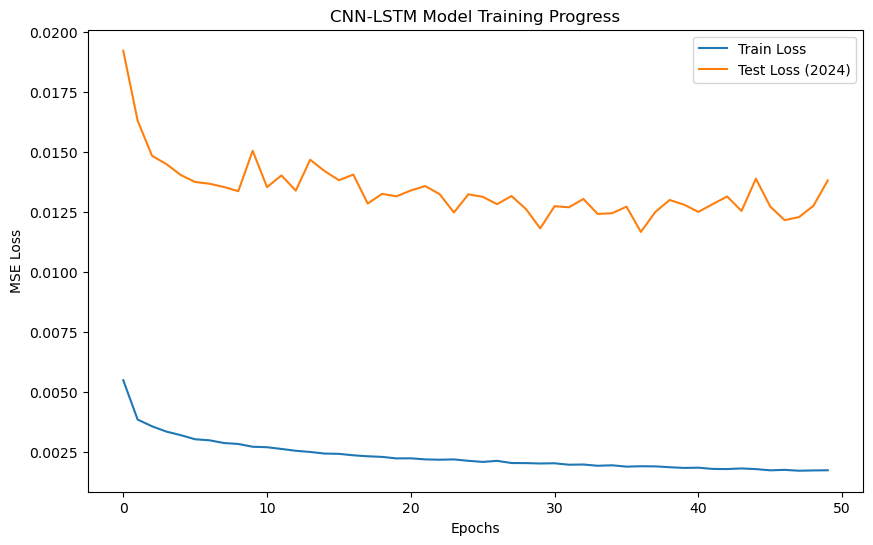

In [17]:
# ==========================================
# 7. PLOT TRAINING HISTORY
# ==========================================
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss (2024)')
plt.title('CNN-LSTM Model Training Progress')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

In [18]:
# Predict
y_pred = model.predict(X_test)

# Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2  = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R2 Score:", r2)

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step
MAE: 0.03076761343535406
MSE: 0.013832069214946932
R2 Score: -4.3568853302014294e+26
